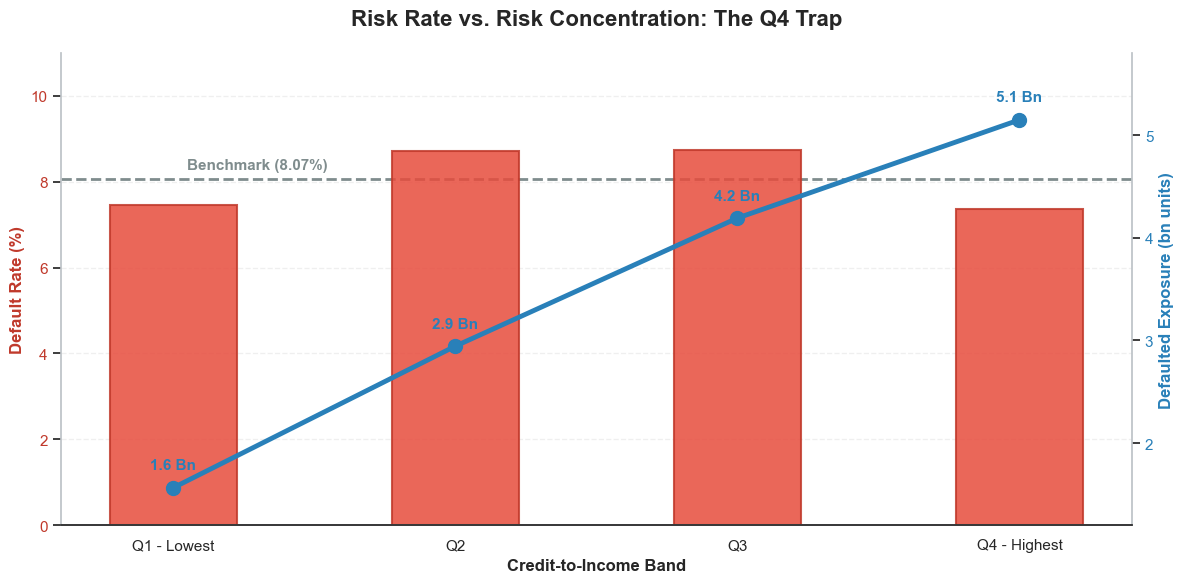

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load processed data
PROCESSED_DIR = Path("../data/processed")
df = pd.read_csv(PROCESSED_DIR / "application_clean.csv")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="white")
fig, ax1 = plt.subplots(figsize=(12, 6), facecolor='white')

# Lấy dữ liệu
q_data = df.groupby("credit_income_band", observed=True).agg(
    default_rate=("target", "mean"),
    defaulted_exp=("amt_credit", lambda x: df.loc[x.index, "target"].eq(1).mul(x).sum() / 1e9)
).reset_index()
q_data["default_rate"] *= 100

# --- TRỤC 1: BIỂU ĐỒ CỘT (Default Rate) ---
# Dùng màu đỏ đô (IndianRed) đậm và sắc nét hơn
bars = ax1.bar(q_data["credit_income_band"], q_data["default_rate"], 
               color='#E74C3C', width=0.45, alpha=0.85, zorder=2, edgecolor='#C0392B', linewidth=1.5)

# Trục Y bên trái
ax1.set_ylabel("Default Rate (%)", color='#C0392B', fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='#C0392B')
ax1.set_ylim(0, 11) # Mở rộng trục Y lên 11 để có không gian cho số liệu đường xanh

# Đường Benchmark 8.07%
ax1.axhline(8.07, color='#7F8C8D', linestyle='--', linewidth=2, zorder=1)
# Đặt text Benchmark ở góc trái, có nền trắng để không bị đè
ax1.text(0.05, 8.3, 'Benchmark (8.07%)', color='#7F8C8D', fontsize=11, 
         fontweight='bold', bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))

# --- TRỤC 2: BIỂU ĐỒ ĐƯỜNG (Defaulted Exposure) ---
ax2 = ax1.twinx()
ax2.plot(q_data["credit_income_band"], q_data["defaulted_exp"], 
         color='#2980B9', marker="o", markersize=10, linewidth=3.5, zorder=3)

# Trục Y bên phải
ax2.set_ylabel("Defaulted Exposure (bn units)", color='#2980B9', fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor='#2980B9')
ax2.set_ylim(1.2, 5.8) # Căn chỉnh lại trục Y phải

# Ghi số liệu lên đầu mỗi điểm (đẩy cao lên hẳn +0.15)
for i, val in enumerate(q_data["defaulted_exp"]):
    ax2.text(i, val + 0.15, f"{val:.1f} Bn", ha='center', va='bottom', 
             color='#2980B9', fontweight='bold', fontsize=11)

# --- TRANG TRÍ CHUNG ---
ax1.set_title("Risk Rate vs. Risk Concentration: The Q4 Trap", fontsize=16, fontweight='bold', pad=20)
ax1.set_xlabel("Credit-to-Income Band", fontsize=12, fontweight='bold')
ax1.grid(axis='y', linestyle='--', alpha=0.3, zorder=0)

# Xóa các viền thừa (Spines)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['left'].set_visible(False)
ax1.spines['left'].set_color('#Bdc3c7')
ax1.spines['bottom'].set_color('#Bdc3c7')
ax2.spines['right'].set_color('#Bdc3c7')

plt.tight_layout()
plt.savefig("../dashboard/Figure3_Q4_Trap_Fixed.png", dpi=300, bbox_inches='tight')
plt.show()

KeyError: 'external_score_band'

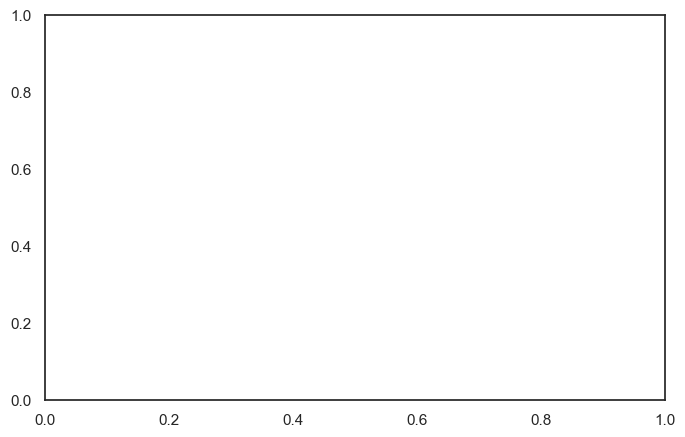

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED_DIR = Path("../data/processed")
df = pd.read_csv(PROCESSED_DIR / "application_clean.csv")

sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(8, 5), facecolor='white')


# Dữ liệu (Giả sử bạn đã load df ở các cell trước)
score_default = df.groupby("external_score_band", observed=True)["target"].mean() * 100

# Vẽ cột với màu đỏ nhạt dần
colors = ['#FADBD8', '#F1948A', '#E74C3C', '#922B21'] 
ax.bar(score_default.index, score_default.values, color=colors, width=0.5, zorder=3)

# Đường Benchmark
ax.axhline(8.07, color='black', linestyle='--', linewidth=2, label='Benchmark (8.07%)')
ax.set_ylabel("Default Rate (%)", fontsize=12, fontweight='bold')
ax.set_title("Default Rate by External Score Band", fontsize=14, fontweight='bold', pad=15)
ax.legend(frameon=False)

# Ghi số trên đầu cột
for i, v in enumerate(score_default.values):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontweight='bold', color='black')

# Xóa viền thừa
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#DDDDDD')
ax.spines['bottom'].set_color('#DDDDDD')
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

plt.tight_layout()
plt.savefig("../dashboard/Figure5_External_Score.png", dpi=300)
plt.show()